In [1]:
from src import utils, argparser, linear_RNN, theory, plotting
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import math

In [2]:
bc = plotting.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [93]:
parser = argparser.get_parser()  
args = parser.parse_args('')
args.frozen_input_output = False
args.frozen_hidden_layer = False
args.input_size = 3
args.hidden_size = 3
args.output_size = 3
args.num_seeds = 1
args.num_SV = 3
args.trajectory_length= 5
args.inout_mode_init = [0.1, 0.1, 0.1] #[0.7, 1, (1/(1.1**args.trajectory_length))]
args.rec_mode_init = [0.1, 0.1, 0.1] #[0.3,0.3]
args.lr = 10
args.num_epochs = 10000

In [94]:
S = torch.zeros((args.trajectory_length, args.output_size, args.input_size)) 
for t in range(1, args.trajectory_length+1):
#     t_S = torch.tensor([0.01, 1.1])
#     t_S = torch.tensor([np.sin(t), np.cos(t)])
#     if t == 1:
#         t_S = torch.tensor([0.1, 0.01])
#     if t == args.trajectory_length: ### IMPORTANT TO HAVE
#         t_S = torch.tensor([1., 0., 0.]) 
#     else:
#         t_S = torch.tensor([np.sin(t), 0.1, 0.5]) 
#     t_S = torch.tensor([np.sin(t), np.cos(t)]) 
#     if t == args.trajectory_length:
#         t_S = torch.tensor([0.7, 0.7**(args.trajectory_length-t), (1/(1.3**args.trajectory_length))])
#     else:
    t_S = torch.tensor([0.7, 0.7**(args.trajectory_length-t), 1.3**t]) #  0.7**t,
    S[t-1] = torch.diag(t_S) 
    # soln for b at [1, 0.7, 1/1.1 ~0.9]
args.S = S
args.num_seeds = 1

args, X, y = utils.generate_data(args)

tape = utils.get_tape_module(args)

args.inout_mode_init = torch.tensor(args.inout_mode_init)
args.rec_mode_init = torch.tensor(args.rec_mode_init)

W_x, W_h, W_y, dW_x, dW_h, dW_y, R_y, R_x = utils.initialize_student(args)

tape.W_x[0,0] = W_x.detach().numpy()
tape.W_h[0,0] = W_h.detach().numpy()
tape.W_y[0,0] = W_y.detach().numpy()
tape.dW_x[0,0] = dW_x.detach().numpy()
tape.dW_h[0,0] = dW_h.detach().numpy()
tape.dW_y[0,0] = dW_y.detach().numpy()
tape.R_y[0,0] = R_y.detach().numpy()
tape.R_x[0,0] = R_x.detach().numpy()

tensor(0.6800)
tensor(0.6756)
tensor(0.6533)
tensor(0.6889)
tensor(0.6800)
tensor(0.6267)
tensor(0.7467)


In [95]:
model = linear_RNN.LinearRNN(args, init_W_x = W_x, init_W_h = W_h, init_W_y = W_y)
losses, W_x_ar, W_h_ar, W_y_ar, H_ar, W_x_grad_ar, W_h_grad_ar = model.train(X,y) ## add tape to model
a_sim,b_sim,c_sim,u_sim = model.project_SVD_space(W_x_ar, W_h_ar, W_y_ar, tape)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


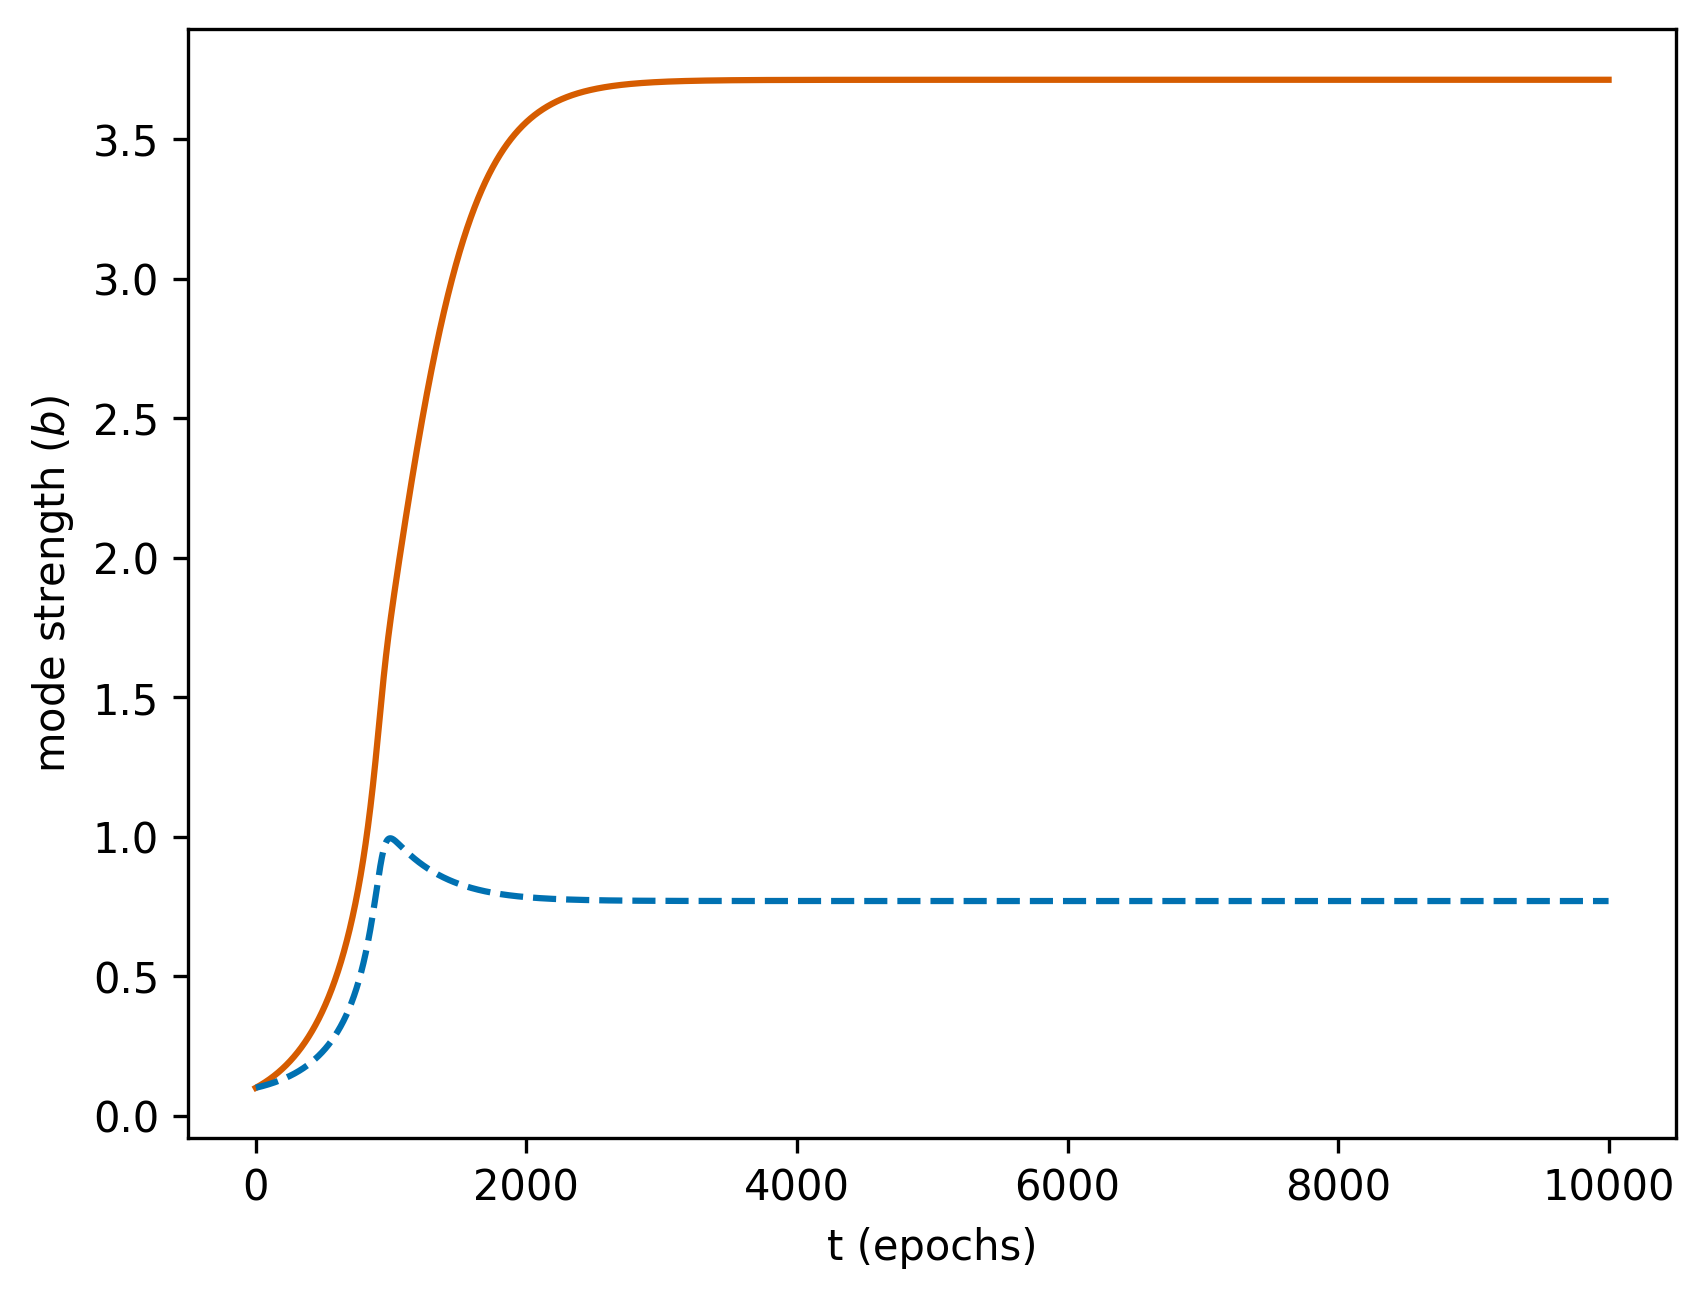

In [96]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
# plt.plot(u_sim[:,0], label=r'$u$', color=blind_colors[0])
# plt.plot(u_sim[:,1], color=blind_colors[0])
plt.plot(u_sim[:,2], color=blind_colors[0])
# plt.plot(b_sim[:,0], label=r'$b$', color=blind_colors[1], ls='dashed')
# plt.plot(b_sim[:,1], color=blind_colors[1], ls='dashed')
plt.plot(b_sim[:,2], color=blind_colors[1], ls='dashed')
# plt.plot([0.01]*20000, color='gray', alpha=0.6)
# plt.plot([1.0]*20000, color='gray', alpha=0.6, label='global solution', ls='dashed')
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'mode strength ($b$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])

In [97]:
print(u_sim[-1,2])
print(b_sim[-1,2])
print(1/1.3)
print(((1.3**args.trajectory_length)))

3.7127462272604386
0.7692314281538007
0.7692307692307692
3.7129300000000005


In [43]:
bound = 0
for i in range(1,11):
    bound += u_sim[-1,0]*(b_sim[-1,0]**(10-i))
#     print(u_sim[-1,1]*b_sim[-1,1]**(10-i))
print(bound)
print(0.1)

0.9995617227894555
0.1
